# Bot & Network Intrusion Detection: Exploratory Data Analysis & Data Cleaning Pipeline
**Dataset:** UNSW-NB15 Benchmark Dataset  
**Project Goal:** Detect whether a website/network connection is affected by malicious bots or cyber attacks  
**Domain:** Network Security & Machine Learning Engineering  

---

### Executive Overview
In real-world cybersecurity, bots and malicious actors rarely behave like organic web visitors. They execute port scans, flood buffers, probe application endpoints, exploit vulnerability signatures, and maintain Command & Control (C2) heartbeats. 

To build a high-performance detection model, we cannot simply feed raw tabular data into an algorithm. In this notebook, we act as Machine Learning Engineers to:
1. **Audit Data Integrity:** Uncover missing values, hidden placeholders (`'-'`), and potential data leakage.
2. **Deep Exploratory Data Analysis (EDA):** Quantify class imbalances, attack family distributions, and protocol behaviors.
3. **Handle Extreme Skewness:** Analyze heavy-tailed network metrics (packet sizes, flow durations, bitrates) and apply variance-stabilizing transformations (`log1p`).
4. **Solve High-Cardinality & Out-of-Vocabulary Categories:** Group rare protocols and states to ensure generalizability.
5. **Construct a Leak-Free Preprocessing Pipeline:** Produce clean, standardized, model-ready datasets exported directly to `Cleaned_DS/`.


In [3]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Sklearn tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, LabelEncoder

# Configure plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10

# Set display options
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 1000)

print("Environment configured successfully. Ready for data ingestion.")


Environment configured successfully. Ready for data ingestion.


## 1. Data Ingestion & Structural Audit
The UNSW-NB15 dataset provides two official partitions:
* `UNSW_NB15_training-set.csv` (82,332 records)
* `UNSW_NB15_testing-set.csv` (175,341 records)

In [4]:
data_dir = "Datasets"
train_path = os.path.join(data_dir, "UNSW_NB15_training-set.csv")
test_path = os.path.join(data_dir, "UNSW_NB15_testing-set.csv")

df_train_raw = pd.read_csv(train_path)
df_test_raw = pd.read_csv(test_path)

print(f"Loaded Training Partition: {df_train_raw.shape[0]:,} rows | {df_train_raw.shape[1]} columns")
print(f"Loaded Testing Partition:  {df_test_raw.shape[0]:,} rows | {df_test_raw.shape[1]} columns")

# Combine both partitions for holistic data auditing & EDA
df_raw = pd.concat([df_train_raw, df_test_raw], ignore_index=True)
print(f"Combined Master Pool:      {df_raw.shape[0]:,} rows | {df_raw.shape[1]} columns")


Loaded Training Partition: 82,332 rows | 45 columns
Loaded Testing Partition:  175,341 rows | 45 columns
Combined Master Pool:      257,673 rows | 45 columns


## 2. Data Quality & Integrity Audit
Before doing any modeling, we must verify:
* Are there null / NaN values?
* Are there artificial ID columns causing target leakage?
* Are there hidden placeholder symbols like `'-'` or whitespace anomalies in categorical columns?


In [5]:
# 1. Null check
null_counts = df_raw.isnull().sum()
print(f"Total NaN / Null values in dataset: {null_counts.sum()}")

# 2. Check for placeholder '-' in categorical columns
cat_cols = ['proto', 'service', 'state', 'attack_cat']
print("\nChecking for placeholder '-' across categorical features:")
for col in cat_cols:
    hyphen_count = (df_raw[col].astype(str) == '-').sum()
    pct = (hyphen_count / len(df_raw)) * 100
    print(f" - {col:12s}: {hyphen_count:>6,} occurrences ({pct:5.2f}%)")

# 3. Check 'id' column:
print(f"\nIs 'id' unique across rows? {df_raw['id'].is_unique} (Train and Test each had their own 1..N indices)")
print("-> 'id' must be dropped as it is an arbitrary index that would cause spurious correlation.")


Total NaN / Null values in dataset: 0

Checking for placeholder '-' across categorical features:
 - proto       :      0 occurrences ( 0.00%)
 - service     : 141,321 occurrences (54.85%)
 - state       :      0 occurrences ( 0.00%)
 - attack_cat  :      0 occurrences ( 0.00%)

Is 'id' unique across rows? False (Train and Test each had their own 1..N indices)
-> 'id' must be dropped as it is an arbitrary index that would cause spurious correlation.


## 3. Exploratory Data Analysis: Target Distributions
In our cybersecurity problem, we have two targets:
1. **`label` (Binary):** `0` = Normal traffic, `1` = Malicious / Bot attack
2. **`attack_cat` (Multi-class):** 10 categories (Normal + 9 attack families: *Generic, Exploits, Fuzzers, DoS, Reconnaissance, Analysis, Backdoor, Shellcode, Worms*)


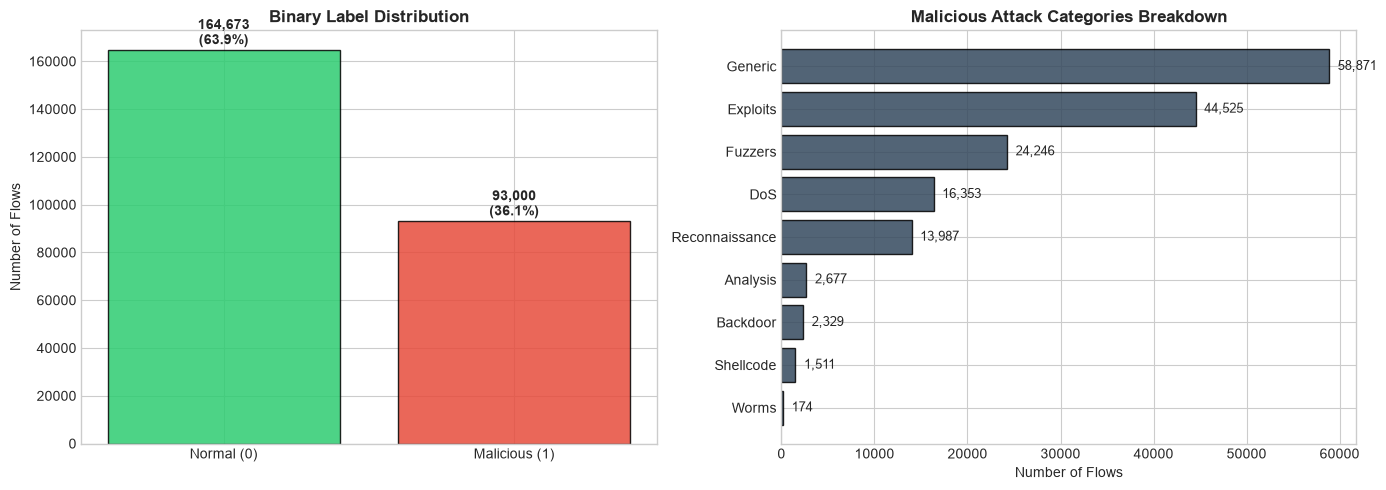

Attack Category Breakdown:
attack_cat
Normal            93000
Generic           58871
Exploits          44525
Fuzzers           24246
DoS               16353
Reconnaissance    13987
Analysis           2677
Backdoor           2329
Shellcode          1511
Worms               174
Name: count, dtype: int64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Binary Label
label_counts = df_raw['label'].value_counts()
label_labels = ['Normal (0)', 'Malicious (1)']
colors_bin = ['#2ecc71', '#e74c3c']
axes[0].bar(label_labels, label_counts.values, color=colors_bin, edgecolor='black', alpha=0.85)
axes[0].set_title('Binary Label Distribution', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Flows')
for i, v in enumerate(label_counts.values):
    axes[0].text(i, v + 2500, f"{v:,}\n({v/len(df_raw)*100:.1f}%)", ha='center', fontweight='bold')

# Plot 2: Attack Categories (excluding Normal for granular attack view)
attack_counts = df_raw[df_raw['attack_cat'] != 'Normal']['attack_cat'].value_counts()
axes[1].barh(attack_counts.index[::-1], attack_counts.values[::-1], color='#34495e', edgecolor='black', alpha=0.85)
axes[1].set_title('Malicious Attack Categories Breakdown', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Flows')
for i, v in enumerate(attack_counts.values[::-1]):
    axes[1].text(v + 500, i, f" {v:,}", va='center', fontsize=9)

plt.tight_layout()
os.makedirs('output_figures', exist_ok=True)
plt.savefig('output_figures/eda_01_label_and_attack_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print("Attack Category Breakdown:")
print(df_raw['attack_cat'].value_counts())


## 4. Categorical Feature Analysis & Cardinality Strategy
Let's inspect the categorical columns: `proto`, `service`, and `state`.
* High cardinality in `proto` (133 protocols) can explode dimensionality and cause out-of-vocabulary errors on test data.
* `service` has `'-'` for non-web / unclassified ports. We must map `'-'` to `'unknown'`.


In [7]:
# Top protocols
top_proto = df_raw['proto'].value_counts()
print(f"Total unique protocols: {len(top_proto)}")
print("\nTop 5 protocols by traffic share:")
for proto, count in top_proto.head(5).items():
    print(f" - {proto:8s}: {count:>7,} ({count/len(df_raw)*100:5.2f}%)")

proto_top3_share = top_proto.head(3).sum() / len(df_raw) * 100
print(f"\nNotice: The top 3 protocols (tcp, udp, arp) account for {proto_top3_share:.2f}% of all traffic!")

# Services analysis
service_counts = df_raw['service'].value_counts()
print(f"\nUnique services: {len(service_counts)}")
print("Service distribution:")
print(service_counts)

# State analysis
state_counts = df_raw['state'].value_counts()
print(f"\nState distribution:")
print(state_counts)


Total unique protocols: 133

Top 5 protocols by traffic share:
 - tcp     : 123,041 (47.75%)
 - udp     :  92,701 (35.98%)
 - unas    :  15,599 ( 6.05%)
 - arp     :   3,846 ( 1.49%)
 - ospf    :   3,271 ( 1.27%)

Notice: The top 3 protocols (tcp, udp, arp) account for 89.78% of all traffic!

Unique services: 13
Service distribution:
service
-           141321
dns          68661
http         27011
smtp          6909
ftp-data      5391
ftp           4980
pop3          1528
ssh           1506
dhcp           120
snmp           109
ssl             86
irc             30
radius          21
Name: count, dtype: int64

State distribution:
state
FIN    117164
INT    116438
CON     20134
REQ      3833
RST        84
ECO        12
ACC         4
CLO         1
PAR         1
URN         1
no          1
Name: count, dtype: int64


## 5. Numerical Feature Skewness & Log-Transformation
Network flow metrics typically obey **power-law / heavy-tailed distributions**:
* A typical web request sends a few hundred bytes, but file transfers or DDoS traffic send gigabytes.
* An average connection lasts 0.05 seconds, but long-lived shells or slowloris attacks persist for hours.

Let's compute the mathematical skewness across all continuous numeric features.


Top 12 Most Heavily Skewed Features:
trans_depth          173.162994
response_body_len     78.477279
sbytes                47.917174
sloss                 47.120682
dloss                 46.086326
dbytes                44.340233
spkts                 42.521898
dpkts                 41.192776
djit                  37.496412
dinpkt                26.965311
ct_flw_http_mthd      20.653962
sjit                  16.864546
dtype: float64


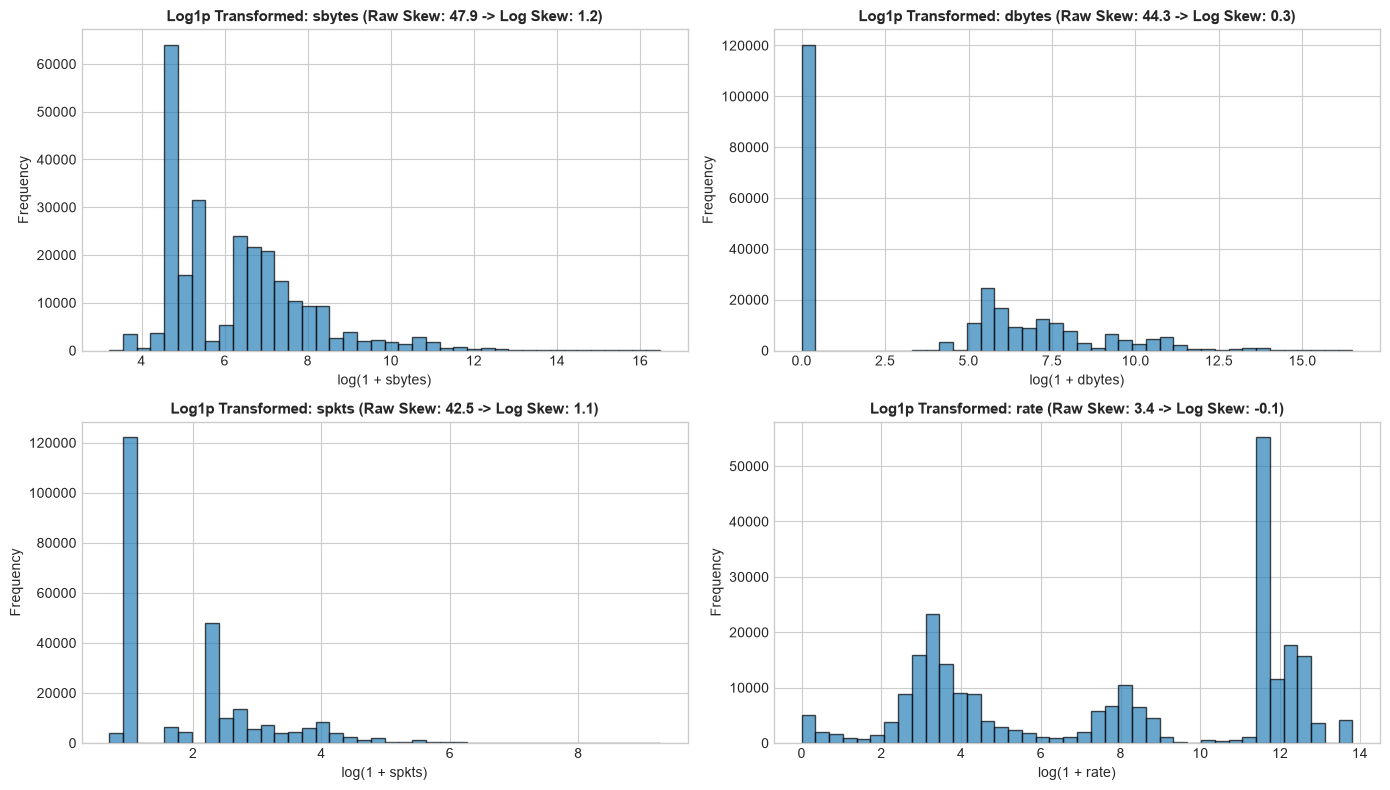

Applying log1p significantly compresses extreme outliers and normalizes variance for machine learning!


In [8]:
num_cols = df_raw.select_dtypes(include=[np.number]).columns.tolist()
num_cols = [c for c in num_cols if c not in ['id', 'label']]

skew_series = df_raw[num_cols].skew().sort_values(ascending=False)
print("Top 12 Most Heavily Skewed Features:")
print(skew_series.head(12))

# Select critical features to visualize before and after log1p transformation
critical_features = ['sbytes', 'dbytes', 'spkts', 'rate']

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for idx, feat in enumerate(critical_features):
    raw_vals = df_raw[feat]
    log_vals = np.log1p(df_raw[feat])
    
    axes[idx].hist(log_vals, bins=40, color='#2980b9', edgecolor='black', alpha=0.7)
    axes[idx].set_title(f'Log1p Transformed: {feat} (Raw Skew: {raw_vals.skew():.1f} -> Log Skew: {log_vals.skew():.1f})', 
                         fontsize=11, fontweight='bold')
    axes[idx].set_xlabel(f'log(1 + {feat})')
    axes[idx].set_ylabel('Frequency')

plt.tight_layout()
os.makedirs('output_figures', exist_ok=True)
plt.savefig('output_figures/eda_02_skewed_features_log1p_transformation.png', dpi=300, bbox_inches='tight')
plt.show()
print("Applying log1p significantly compresses extreme outliers and normalizes variance for machine learning!")


## 6. Correlation Matrix & Multicollinearity Screening
Let's inspect the linear correlations between key network flow metrics to identify redundant features (e.g., `spkts` vs `sbytes`, `sloss` vs `spkts`).


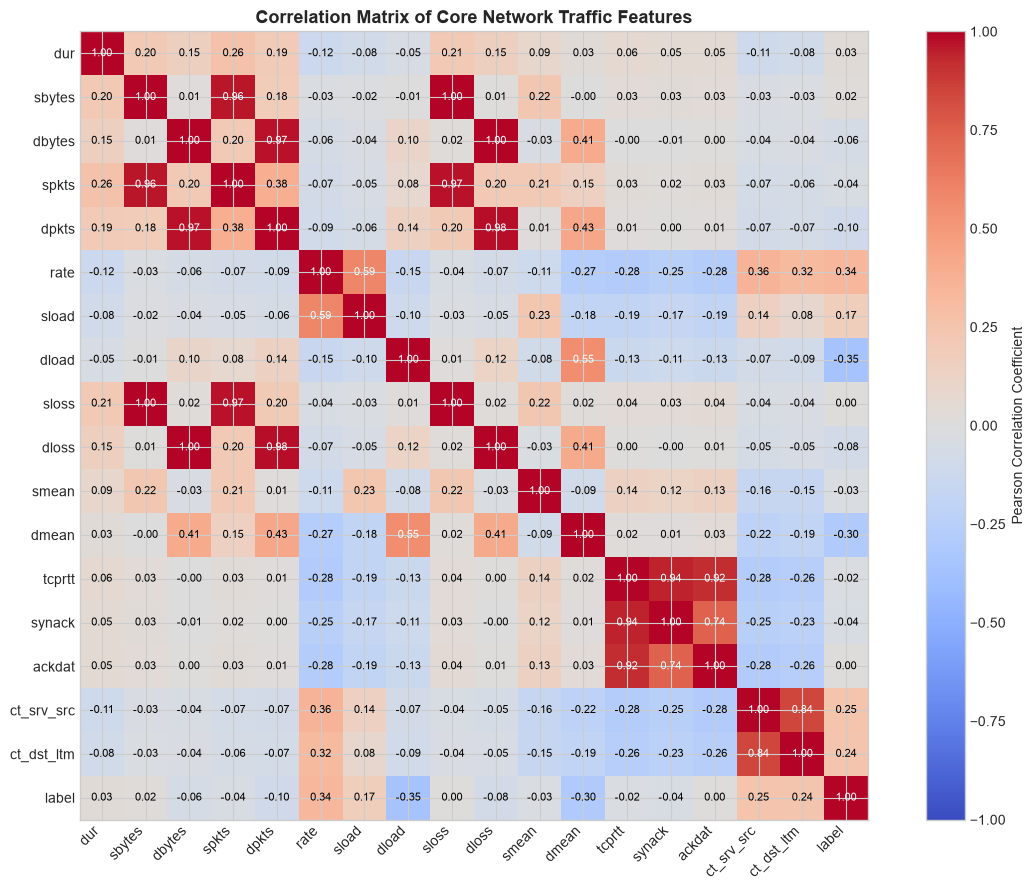

In [9]:
selected_corr_features = [
    'dur', 'sbytes', 'dbytes', 'spkts', 'dpkts', 'rate', 
    'sload', 'dload', 'sloss', 'dloss', 'smean', 'dmean', 
    'tcprtt', 'synack', 'ackdat', 'ct_srv_src', 'ct_dst_ltm', 'label'
]

corr_matrix = df_raw[selected_corr_features].corr()

plt.figure(figsize=(12, 9))
plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Pearson Correlation Coefficient')
plt.xticks(range(len(selected_corr_features)), selected_corr_features, rotation=45, ha='right')
plt.yticks(range(len(selected_corr_features)), selected_corr_features)
plt.title('Correlation Matrix of Core Network Traffic Features', fontsize=13, fontweight='bold')

# Annotate correlation values
for i in range(len(selected_corr_features)):
    for j in range(len(selected_corr_features)):
        val = corr_matrix.iloc[i, j]
        plt.text(j, i, f"{val:.2f}", ha='center', va='center', 
                 color='white' if abs(val) > 0.5 else 'black', fontsize=8)

plt.tight_layout()
os.makedirs('output_figures', exist_ok=True)
plt.savefig('output_figures/eda_03_feature_correlation_matrix.png', dpi=300, bbox_inches='tight')
plt.show()


## 7. Production-Grade Data Cleaning & Preprocessing Pipeline

Based on our exploratory findings, our ML engineering pipeline will:
1. **Drop `id`:** Avoid spurious correlation.
2. **Clean `service`:** Replace placeholder `'-'` with `'unknown'`.
3. **Handle High-Cardinality Categoricals:**
   * In `proto`: Keep the top protocols (`tcp`, `udp`, `arp`, `ospf`), collapse all rare protocols into `'other'`.
   * In `state`: Keep high-frequency states (`FIN`, `INT`, `CON`, `REQ`, `RST`), collapse rare ones into `'other'`.
4. **Log-Transform Heavy-Tailed Features:** Apply `np.log1p` to features with extreme skewness (> 5.0) like `sbytes`, `dbytes`, `spkts`, `dpkts`, `sload`, `dload`, `rate`, `dur`, `response_body_len`, `djit`, `sjit`.
5. **Encode Categoricals:** Perform One-Hot Encoding on nominal features (`proto`, `service`, `state`).
6. **Train-Test Stratified Split (80 / 20):** Split before scaling to guarantee zero data leakage.
7. **Scale Continuous Features:** Fit `RobustScaler` on the training set and transform the test set.
8. **Export Datasets to `Cleaned_DS/`:**
   * `train_cleaned.csv`
   * `test_cleaned.csv`
   * `unsw_nb15_cleaned_master.csv`
   * `feature_metadata.json`


In [10]:
# Step 1: Clean a master copy of the dataframe
df_clean = df_raw.copy()

# Drop identifier
if 'id' in df_clean.columns:
    df_clean = df_clean.drop(columns=['id'])

# Clean 'service' placeholder
df_clean['service'] = df_clean['service'].replace({'-': 'unknown'})

# Group rare protocols (< 500 occurrences collapsed into 'other')
proto_counts = df_clean['proto'].value_counts()
rare_protos = proto_counts[proto_counts < 500].index
df_clean.loc[df_clean['proto'].isin(rare_protos), 'proto'] = 'other'
print(f"Reduced 'proto' cardinality from {len(proto_counts)} to {df_clean['proto'].nunique()} categories.")

# Group rare states (< 100 occurrences collapsed into 'other')
state_counts = df_clean['state'].value_counts()
rare_states = state_counts[state_counts < 100].index
df_clean.loc[df_clean['state'].isin(rare_states), 'state'] = 'other'
print(f"Reduced 'state' cardinality from {len(state_counts)} to {df_clean['state'].nunique()} categories.")

# Apply log1p on heavily skewed volume & duration features
skewed_features = [
    'dur', 'sbytes', 'dbytes', 'spkts', 'dpkts', 
    'sload', 'dload', 'rate', 'sloss', 'dloss', 
    'sjit', 'djit', 'sinpkt', 'dinpkt', 'tcprtt', 
    'synack', 'ackdat', 'response_body_len'
]

for col in skewed_features:
    if col in df_clean.columns:
        df_clean[col] = np.log1p(np.maximum(df_clean[col], 0))

print(f"Applied log1p transformation to {len(skewed_features)} heavy-tailed numerical features.")

# Preserve target variables
y_binary = df_clean['label'].values
y_multiclass = df_clean['attack_cat'].values

# Feature matrix before one-hot encoding
X_pre_ohe = df_clean.drop(columns=['label', 'attack_cat'])

# One-hot encode categoricals: proto, service, state
categorical_features = ['proto', 'service', 'state']
X_encoded = pd.get_dummies(X_pre_ohe, columns=categorical_features, drop_first=True, dtype=int)

print(f"Engineered Feature Matrix shape: {X_encoded.shape[0]:,} samples, {X_encoded.shape[1]} features")


Reduced 'proto' cardinality from 133 to 7 categories.
Reduced 'state' cardinality from 11 to 5 categories.
Applied log1p transformation to 18 heavy-tailed numerical features.
Engineered Feature Matrix shape: 257,673 samples, 61 features


In [11]:
# Step 2: Stratified Split (80% Training, 20% Testing)
X_train_df, X_test_df, y_train_bin, y_test_bin, y_train_multi, y_test_multi = train_test_split(
    X_encoded, y_binary, y_multiclass, 
    test_size=0.20, 
    random_state=42, 
    stratify=y_binary
)

print(f"Training set: {X_train_df.shape[0]:,} samples | Testing set: {X_test_df.shape[0]:,} samples")
print(f"Training malicious ratio: {np.mean(y_train_bin)*100:.2f}% | Testing malicious ratio: {np.mean(y_test_bin)*100:.2f}%")

# Step 3: Feature Scaling using RobustScaler (fitted strictly on X_train to prevent leakage)
continuous_cols = [c for c in X_encoded.columns if not any(c.startswith(f"{cat}_") for cat in categorical_features)]

scaler = RobustScaler()
X_train_scaled = X_train_df.copy()
X_test_scaled = X_test_df.copy()

X_train_scaled[continuous_cols] = scaler.fit_transform(X_train_df[continuous_cols])
X_test_scaled[continuous_cols] = scaler.transform(X_test_df[continuous_cols])

# Attach targets to train and test sets
train_cleaned = X_train_scaled.copy()
train_cleaned['attack_cat'] = y_train_multi
train_cleaned['label'] = y_train_bin

test_cleaned = X_test_scaled.copy()
test_cleaned['attack_cat'] = y_test_multi
test_cleaned['label'] = y_test_bin

# Assemble the full master cleaned dataset
master_cleaned = pd.concat([train_cleaned, test_cleaned], ignore_index=True)


Training set: 206,138 samples | Testing set: 51,535 samples
Training malicious ratio: 63.91% | Testing malicious ratio: 63.91%


## 8. Exporting Cleaned Datasets to `Cleaned_DS/`
We now save:
1. `Cleaned_DS/train_cleaned.csv`: 80% partitioned, scaled, encoded, zero leakage.
2. `Cleaned_DS/test_cleaned.csv`: 20% partitioned, scaled using train statistics.
3. `Cleaned_DS/unsw_nb15_cleaned_master.csv`: Unified cleaned dataset.
4. `Cleaned_DS/feature_metadata.json`: Feature list, types, and summary statistics.


In [12]:
output_dir = "Cleaned_DS"
os.makedirs(output_dir, exist_ok=True)

train_file = os.path.join(output_dir, "train_cleaned.csv")
test_file = os.path.join(output_dir, "test_cleaned.csv")
master_file = os.path.join(output_dir, "unsw_nb15_cleaned_master.csv")
meta_file = os.path.join(output_dir, "feature_metadata.json")

print("Saving cleaned datasets to Cleaned_DS/...")
train_cleaned.to_csv(train_file, index=False)
test_cleaned.to_csv(test_file, index=False)
master_cleaned.to_csv(master_file, index=False)

# Export feature metadata
metadata = {
    "total_samples": int(len(master_cleaned)),
    "train_samples": int(len(train_cleaned)),
    "test_samples": int(len(test_cleaned)),
    "feature_count": int(X_encoded.shape[1]),
    "features": list(X_encoded.columns),
    "continuous_features": continuous_cols,
    "target_binary": "label",
    "target_multiclass": "attack_cat",
    "normal_samples": int((master_cleaned['label'] == 0).sum()),
    "attack_samples": int((master_cleaned['label'] == 1).sum()),
    "attack_categories": {k: int(v) for k, v in master_cleaned['attack_cat'].value_counts().items()}
}

with open(meta_file, 'w') as f:
    json.dump(metadata, f, indent=4)

print("\n[SUCCESS] Datasets saved successfully!")
for fname in os.listdir(output_dir):
    fpath = os.path.join(output_dir, fname)
    size_mb = os.path.getsize(fpath) / (1024 * 1024)
    print(f" - {fname:30s} ({size_mb:.2f} MB)")


Saving cleaned datasets to Cleaned_DS/...

[SUCCESS] Datasets saved successfully!
 - feature_metadata.json          (0.00 MB)
 - test_cleaned.csv               (26.09 MB)
 - train_cleaned.csv              (104.46 MB)
 - unsw_nb15_cleaned_master.csv   (130.55 MB)
